# SOC Development Along Routes - With 50% Destination Constraint

This notebook visualizes State of Charge (SOC) development along transport routes, including:
- SOC values at each geographic node
- Charging events at each node
- Energy consumption between nodes
- Verification of the 50% destination SOC constraint

**Constraint**: `soc[destination] = 0.5 × tank_capacity × num_vehicles`

In [1]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re
from pathlib import Path
from collections import defaultdict

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

## 1. Configuration and Data Loading

In [2]:
# Configuration
base_path = Path("C:/Users/simuser/Documents/AntoniaGolab/Scand_Med_analysis/SM_baby_2/iDesignRES_transcompmodel/examples/moving_loads_SM")

# Case to analyze
case_name = "case_20251110_160304_var_var"
result_timestamp = "case_20251110_160304_var_var_cs_2025-11-18_10-44-39"

input_dir = base_path / "input_data" / case_name
results_dir = base_path / "results" / case_name

# Analysis parameters
target_year = 2056
bev_id = 1  # BEV techvehicle ID
target_generation = 2056  # Can be changed to analyze different generations

print(f"Analyzing case: {case_name}")
print(f"Results: {result_timestamp}")
print(f"Target year: {target_year}, Generation: {target_generation}, Vehicle: BEV (id={bev_id})")

Analyzing case: case_20251110_160304_var_var
Results: case_20251110_160304_var_var_cs_2025-11-18_10-44-39
Target year: 2056, Generation: 2056, Vehicle: BEV (id=1)


In [ ]:
# Key parsing functions
def parse_soc_key(key_str):
    """Parse soc_dict key: (year, (product, odpair, path, geo), techvehicle, generation)"""
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*(\d+)\)'
    match = re.match(pattern, key_str)
    if match:
        return {
            'year': int(match.group(1)),
            'product': int(match.group(2)),
            'odpair': int(match.group(3)),
            'path': int(match.group(4)),
            'geo': int(match.group(5)),
            'techvehicle': int(match.group(6)),
            'generation': int(match.group(7))
        }
    return None

def parse_s_key(key_str):
    """Parse s_dict key: (year, (product, odpair, path, geo), techvehicle, (fuel, infra), generation)"""
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
    match = re.match(pattern, key_str)
    if match:
        return {
            'year': int(match.group(1)),
            'product': int(match.group(2)),
            'odpair': int(match.group(3)),
            'path': int(match.group(4)),
            'geo': int(match.group(5)),
            'techvehicle': int(match.group(6)),
            'fuel': int(match.group(7)),
            'infra': int(match.group(8)),
            'generation': int(match.group(9))
        }
    return None

def parse_f_key(key_str):
    """Parse f_dict key: (year, (product, odpair, path), (mode, techvehicle), generation)"""
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
    match = re.match(pattern, key_str)
    if match:
        return {
            'year': int(match.group(1)),
            'product': int(match.group(2)),
            'odpair': int(match.group(3)),
            'path': int(match.group(4)),
            'mode': int(match.group(5)),
            'techvehicle': int(match.group(6)),
            'generation': int(match.group(7))
        }
    return None

In [4]:
# Load input data
print("Loading input data...")
with open(input_dir / "Path.yaml", 'r', encoding='utf-8') as f:
    paths = yaml.safe_load(f)

with open(input_dir / "TechVehicle.yaml", 'r', encoding='utf-8') as f:
    techvehicles = yaml.safe_load(f)

with open(input_dir / "Model.yaml", 'r', encoding='utf-8') as f:
    model_data = yaml.safe_load(f)

# Try to load GeographicElement.yaml (optional, for geographic names)
geo_elements = []
try:
    with open(input_dir / "GeographicElement.yaml", 'r', encoding='utf-8') as f:
        geo_elements = yaml.safe_load(f)
    print(f"Loaded {len(geo_elements)} geo elements")
except FileNotFoundError:
    print("GeographicElement.yaml not found - geographic names will not be available")
    geo_elements = []

# Calculate g_init from Model parameters
y_init = model_data["y_init"]
pre_y = model_data["pre_y"]
g_init = y_init - pre_y

print(f"Model parameters: y_init={y_init}, pre_y={pre_y}, g_init={g_init}")
print(f"Loaded {len(paths)} paths, {len(techvehicles)} techvehicles")

Loading input data...
Loaded 81 geo elements
Model parameters: y_init=2020, pre_y=12, g_init=2008
Loaded 2210 paths, 2 techvehicles


In [5]:
# Load results
print("Loading results...")
with open(results_dir / f"{result_timestamp}_soc_dict.yaml", 'r', encoding='utf-8') as f:
    soc_dict = yaml.safe_load(f)

with open(results_dir / f"{result_timestamp}_s_dict.yaml", 'r', encoding='utf-8') as f:
    s_dict = yaml.safe_load(f)

with open(results_dir / f"{result_timestamp}_f_dict.yaml", 'r', encoding='utf-8') as f:
    f_dict = yaml.safe_load(f)

print(f"Loaded {len(soc_dict):,} SOC entries")
print(f"Loaded {len(s_dict):,} charging entries")
print(f"Loaded {len(f_dict):,} flow entries")

Loading results...
Loaded 1,070,369 SOC entries
Loaded 1,216,297 charging entries
Loaded 127,618 flow entries


In [6]:
# Build lookups
path_dict = {p['id']: p for p in paths}
tv_dict = {tv['id']: tv for tv in techvehicles}
geo_dict = {g['id']: g for g in geo_elements}

# Get BEV info
bev = tv_dict[bev_id]
gen_idx = target_generation - g_init

if gen_idx >= 0 and gen_idx < len(bev['tank_capacity']):
    tank_capacity = bev['tank_capacity'][gen_idx]
    W = bev['W'][gen_idx]
    AnnualRange = bev['AnnualRange'][gen_idx]
    spec_cons = bev['spec_cons'][gen_idx]
    
    print(f"\nBEV parameters for generation {target_generation} (index {gen_idx}):")
    print(f"  Tank capacity: {tank_capacity:.2f} kWh")
    print(f"  W (payload weight): {W:.2f} tonnes")
    print(f"  Annual range: {AnnualRange:.2f} km")
    print(f"  Specific consumption: {spec_cons:.4f} kWh/tonne-km")
else:
    print(f"ERROR: Generation index {gen_idx} out of range!")


BEV parameters for generation 2056 (index 48):
  Tank capacity: 1187.00 kWh
  W (payload weight): 11.22 tonnes
  Annual range: 136750.00 km
  Specific consumption: 1.2100 kWh/tonne-km


## 2. Find Paths with BEV Flow

In [7]:
# Find all paths with BEV flow in target year and generation
paths_with_bev = {}

for key_str, value in f_dict.items():
    parsed = parse_f_key(key_str)
    if (parsed and 
        parsed['year'] == target_year and 
        parsed['techvehicle'] == bev_id and
        parsed['generation'] == target_generation):
        val = float(value) if isinstance(value, str) else value
        if val > 0.01:  # Only paths with significant flow
            path_id = parsed['path']
            if path_id in path_dict:  # Verify path exists
                paths_with_bev[path_id] = val

print(f"Found {len(paths_with_bev)} paths with BEV flow")

# Sort by flow and show top 20
top_paths = sorted(paths_with_bev.items(), key=lambda x: x[1], reverse=True)[:20]

print(f"\nTop 20 paths by BEV flow:")
print(f"{'Path ID':<10} {'Flow':<12} {'Length (km)':<15} {'Num Nodes'}")
print("-" * 55)

for path_id, flow in top_paths:
    path = path_dict[path_id]
    print(f"{path_id:<10} {flow:<12.4f} {path['length']:<15.2f} {len(path['sequence'])}")

Found 1497 paths with BEV flow

Top 20 paths by BEV flow:
Path ID    Flow         Length (km)     Num Nodes
-------------------------------------------------------
1566       132.7926     1093.19         11
806        126.4454     1130.22         10
1564       108.0334     1016.68         11
767        106.7050     1087.59         11
1718       104.0212     1099.48         10
590        90.1861      1157.48         12
1557       89.8044      1122.95         11
802        89.7213      1014.21         12
1559       84.1759      1157.44         12
1719       81.9813      1044.11         10
841        76.2575      1061.50         10
1813       73.9123      1111.43         11
1717       71.0457      1258.05         10
808        69.4999      1095.97         11
926        69.1672      1107.67         9
1484       67.4778      1186.03         12
2152       66.1176      555.08          3
531        64.6727      1112.84         11
1722       63.0939      1086.83         9
1580       62.8822    

## 3. Select a Path to Visualize

In [8]:
# Select path to visualize (use the path with highest flow, or change to any path_id)
selected_path_id = top_paths[0][0] if top_paths else None

# Or manually select a path:
# selected_path_id = 1129  # Example path ID

if selected_path_id is None:
    print("ERROR: No paths with BEV flow found!")
else:
    selected_path = path_dict[selected_path_id]
    selected_flow = paths_with_bev[selected_path_id]
    
    print(f"Selected path ID: {selected_path_id}")
    print(f"Flow: {selected_flow:.4f}")
    print(f"Length: {selected_path['length']:.2f} km")
    print(f"Number of nodes: {len(selected_path['sequence'])}")

Selected path ID: 1566
Flow: 132.7926
Length: 1093.19 km
Number of nodes: 11


## 4. Extract SOC and Charging Data for Selected Path

In [9]:
if selected_path_id is not None:
    # Get path sequence
    sequence = selected_path['sequence']
    
    # Handle both dict and int formats in sequence
    geo_ids = []
    for item in sequence:
        if isinstance(item, dict):
            geo_ids.append(item['id'])
        else:
            geo_ids.append(item)
    
    print(f"Geographic sequence ({len(geo_ids)} nodes): {geo_ids[:10]}..." if len(geo_ids) > 10 else f"Geographic sequence: {geo_ids}")
    
    # Extract SOC values along the route
    soc_values = {}
    for key_str, value in soc_dict.items():
        parsed = parse_soc_key(key_str)
        if (parsed and
            parsed['year'] == target_year and
            parsed['path'] == selected_path_id and
            parsed['techvehicle'] == bev_id and
            parsed['generation'] == target_generation):
            geo_id = parsed['geo']
            val = float(value) if isinstance(value, str) else value
            soc_values[geo_id] = val  # Already in kWh
    
    # Extract charging values along the route
    charging_values = defaultdict(float)
    for key_str, value in s_dict.items():
        parsed = parse_s_key(key_str)
        if (parsed and
            parsed['year'] == target_year and
            parsed['path'] == selected_path_id and
            parsed['techvehicle'] == bev_id and
            parsed['generation'] == target_generation):
            geo_id = parsed['geo']
            val = float(value) if isinstance(value, str) else value
            charging_values[geo_id] += val * 1000  # Convert from MWh to kWh
    
    print(f"\nFound SOC values at {len(soc_values)} nodes")
    print(f"Found charging at {len(charging_values)} nodes")
    
    # Create ordered arrays for plotting
    soc_array = [soc_values.get(geo_id, 0) for geo_id in geo_ids]
    charging_array = [charging_values.get(geo_id, 0) for geo_id in geo_ids]
    
    # Calculate consumption between nodes - DISPLAYED AT ARRIVAL NODE
    # IMPORTANT: The model uses charging[i+1] not charging[i]
    # SOC[i+1] = SOC[i] - consumption[i→i+1] + charging[i+1]
    # Therefore: consumption[i→i+1] = SOC[i] - SOC[i+1] + charging[i+1]
    #
    # consumption_array[0] = 0 (no consumption to arrive at origin)
    # consumption_array[i] = energy consumed FROM node i-1 TO arrive at node i
    consumption_array = [0]  # No consumption to arrive at origin
    for i in range(len(soc_array) - 1):
        # Consumption from node i to node i+1 (will be displayed at node i+1)
        consumption = soc_array[i] + charging_array[i+1] - soc_array[i+1]
        consumption_array.append(consumption)
    
    print(f"\nSOC at origin: {soc_array[0]:.2f} kWh")
    print(f"SOC at destination: {soc_array[-1]:.2f} kWh")
    print(f"Total charging: {sum(charging_array):.2f} kWh")
    print(f"Total consumption: {sum(consumption_array):.2f} kWh")

Geographic sequence (11 nodes): [51, 60, 59, 58, 2, 8, 12, 13, 21, 30]...

Found SOC values at 11 nodes
Found charging at 10 nodes

SOC at origin: 112305.47 kWh
SOC at destination: 56152.74 kWh
Total charging: 68997.61 kWh
Total consumption: 125150.34 kWh


## 5. Verify 50% Destination Constraint

In [10]:
if selected_path_id is not None:
    # Calculate expected SOC at destination based on 50% constraint
    # num_vehicles = (path_length / (W × AnnualRange)) × 1000 × f
    num_vehicles = (selected_path['length'] / (W * AnnualRange)) * 1000 * selected_flow
    expected_soc_dest = 0.5 * tank_capacity * num_vehicles
    
    actual_soc_dest = soc_array[-1]
    
    print(f"\n{'='*80}")
    print(f"50% DESTINATION SOC CONSTRAINT VERIFICATION")
    print(f"{'='*80}")
    print(f"\nPath: {selected_path_id}, Year: {target_year}, Generation: {target_generation}")
    print(f"\nCalculation:")
    print(f"  Path length:              {selected_path['length']:>12.4f} km")
    print(f"  W[{gen_idx}]:                    {W:>12.4f} tonnes")
    print(f"  AnnualRange[{gen_idx}]:          {AnnualRange:>12.4f} km")
    print(f"  tank_capacity[{gen_idx}]:        {tank_capacity:>12.4f} kWh")
    print(f"  Flow (f):                 {selected_flow:>12.8f}")
    print(f"\n  Num vehicles:             {num_vehicles:>12.8f}")
    print(f"  Expected SOC (50%):       {expected_soc_dest:>12.4f} kWh")
    print(f"  Actual SOC:               {actual_soc_dest:>12.4f} kWh")
    print(f"\n  Difference:               {(actual_soc_dest - expected_soc_dest):>12.4f} kWh")
    print(f"  Ratio (actual/expected):  {(actual_soc_dest / expected_soc_dest):>12.8f}")
    
    tolerance = 1e-3
    if abs(actual_soc_dest - expected_soc_dest) < tolerance:
        print(f"\n  ✓ 50% constraint SATISFIED (within {tolerance} kWh tolerance)")
    else:
        print(f"\n  ✗ 50% constraint VIOLATED (exceeds {tolerance} kWh tolerance)")
    print(f"\n{'='*80}")


50% DESTINATION SOC CONSTRAINT VERIFICATION

Path: 1566, Year: 2056, Generation: 2056

Calculation:
  Path length:                 1093.1921 km
  W[48]:                         11.2200 tonnes
  AnnualRange[48]:           136750.0000 km
  tank_capacity[48]:           1187.0000 kWh
  Flow (f):                 132.79261000

  Num vehicles:              94.61286538
  Expected SOC (50%):         56152.7356 kWh
  Actual SOC:                 56152.7358 kWh

  Difference:                     0.0002 kWh
  Ratio (actual/expected):    1.00000000

  ✓ 50% constraint SATISFIED (within 0.001 kWh tolerance)



## 6. Visualize SOC Development Along Route

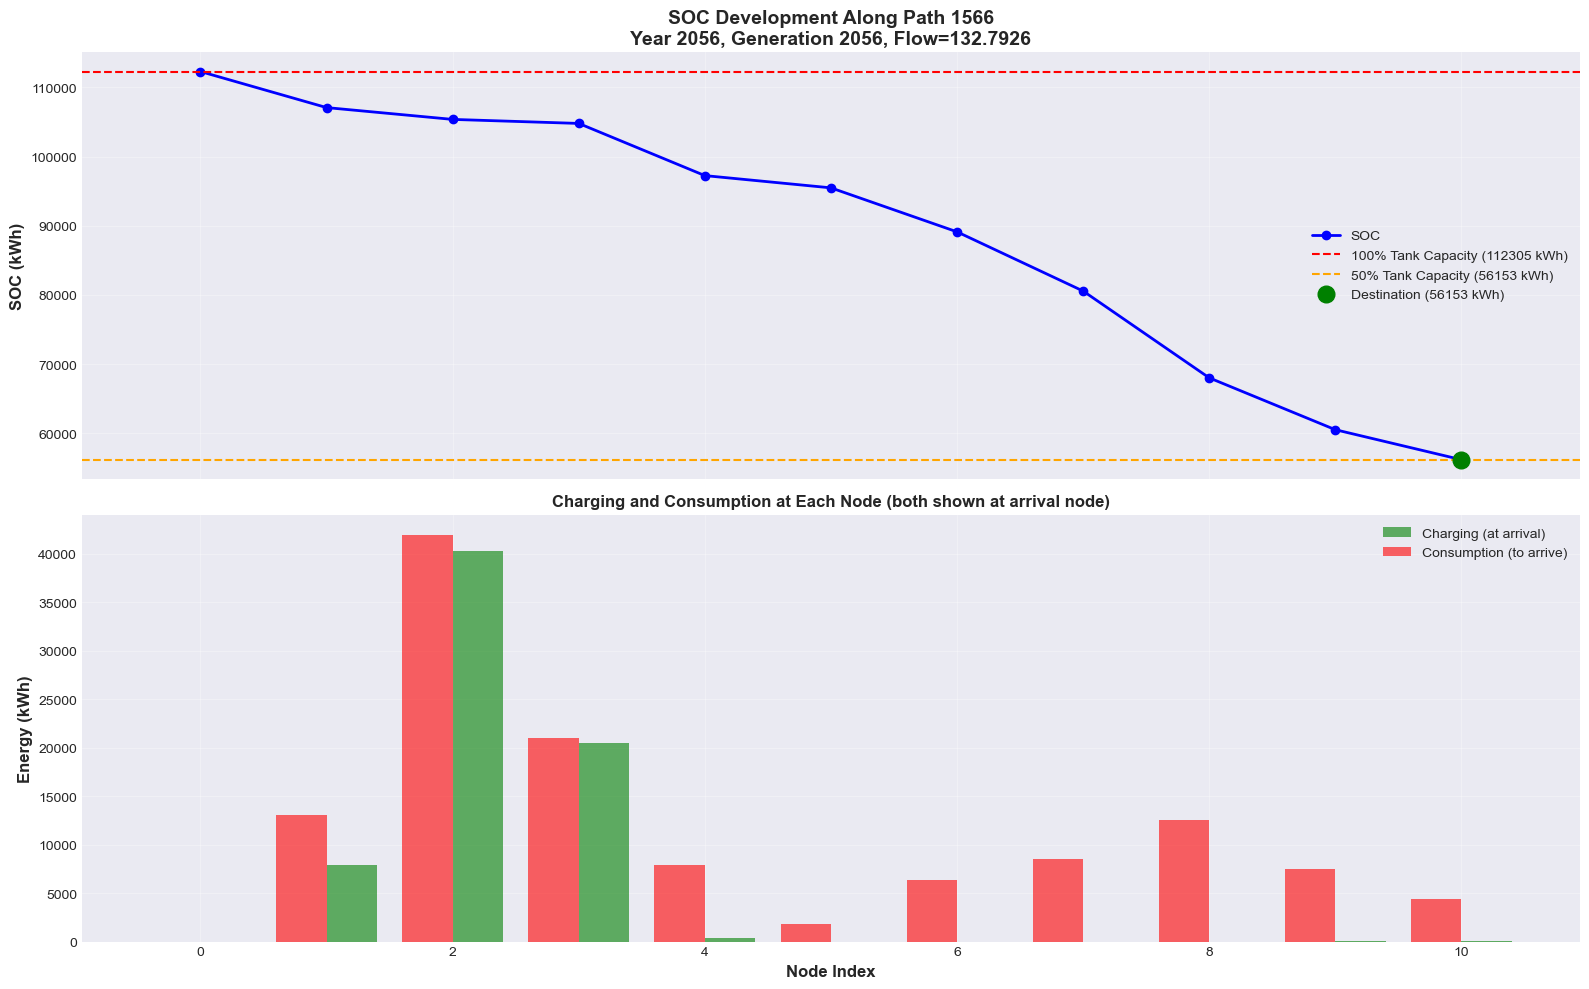


Figure saved as: soc_development_path_1566_gen_2056.pdf


In [11]:
if selected_path_id is not None:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)
    
    node_positions = np.arange(len(geo_ids))
    
    # Top plot: SOC values and tank capacity
    ax1.plot(node_positions, soc_array, 'b-o', linewidth=2, markersize=6, label='SOC')
    
    # Add horizontal line for tank capacity and 50% tank capacity
    total_tank_capacity = tank_capacity * num_vehicles
    ax1.axhline(y=total_tank_capacity, color='r', linestyle='--', linewidth=1.5, label=f'100% Tank Capacity ({total_tank_capacity:.0f} kWh)')
    ax1.axhline(y=0.5 * total_tank_capacity, color='orange', linestyle='--', linewidth=1.5, label=f'50% Tank Capacity ({0.5*total_tank_capacity:.0f} kWh)')
    
    # Highlight destination point
    ax1.plot(node_positions[-1], soc_array[-1], 'go', markersize=12, label=f'Destination ({soc_array[-1]:.0f} kWh)', zorder=5)
    
    ax1.set_ylabel('SOC (kWh)', fontsize=12, fontweight='bold')
    ax1.set_title(f'SOC Development Along Path {selected_path_id}\nYear {target_year}, Generation {target_generation}, Flow={selected_flow:.4f}', 
                  fontsize=14, fontweight='bold')
    ax1.legend(loc='best')
    ax1.grid(True, alpha=0.3)
    
    # Bottom plot: Charging and Consumption
    # Note: Consumption at node i shows energy consumed to ARRIVE at node i (from node i-1)
    ax2.bar(node_positions, charging_array, color='green', alpha=0.6, label='Charging (at arrival)', width=0.4, align='edge')
    ax2.bar(node_positions - 0.4, consumption_array, color='red', alpha=0.6, label='Consumption (to arrive)', width=0.4, align='edge')
    
    ax2.set_xlabel('Node Index', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Energy (kWh)', fontsize=12, fontweight='bold')
    ax2.set_title('Charging and Consumption at Each Node (both shown at arrival node)', fontsize=12, fontweight='bold')
    ax2.legend(loc='best')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'soc_development_path_{selected_path_id}_gen_{target_generation}.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\nFigure saved as: soc_development_path_{selected_path_id}_gen_{target_generation}.pdf")

## 7. Detailed Node-by-Node Breakdown

In [12]:
if selected_path_id is not None:
    # Create detailed dataframe
    # NOTE: 
    #   - SOC (kWh): State of charge AT this node
    #   - Charging (kWh): Energy charged AT this node (after arrival)
    #   - Consumption (kWh): Energy consumed TO ARRIVE at this node (from previous node)
    #     * Node 0: consumption = 0 (origin, no travel to arrive)
    #     * Node i: consumption from node i-1 to arrive at node i
    data = []
    for i, geo_id in enumerate(geo_ids):
        # Get geo name if available
        geo_name = geo_dict.get(geo_id, {}).get('name', f'Geo_{geo_id}')
        
        row = {
            'Node': i,
            'Geo_ID': geo_id,
            'Geo_Name': geo_name,
            'SOC (kWh)': soc_array[i],
            'Charging (kWh)': charging_array[i],
            'Consumption (kWh)': consumption_array[i],
            'SOC % of Tank': (soc_array[i] / total_tank_capacity * 100) if total_tank_capacity > 0 else 0
        }
        data.append(row)
    
    df = pd.DataFrame(data)
    
    print(f"\nDetailed Node-by-Node Breakdown for Path {selected_path_id}:")
    print(f"Note: Consumption shown at arrival node (energy consumed FROM previous node TO arrive at this node)")
    print("=" * 120)
    print(df.to_string(index=False))
    print("=" * 120)
    
    # Save to CSV
    csv_filename = f'soc_detailed_path_{selected_path_id}_gen_{target_generation}.csv'
    df.to_csv(csv_filename, index=False)
    print(f"\nDetailed data saved to: {csv_filename}")
    
    # Print energy balance verification for first few transitions
    print(f"\nEnergy Balance Verification (first 3 transitions):")
    print("=" * 120)
    for i in range(min(3, len(soc_array) - 1)):
        expected_soc = soc_array[i] - consumption_array[i+1] + charging_array[i+1]
        actual_soc = soc_array[i+1]
        diff = abs(expected_soc - actual_soc)
        status = "OK" if diff < 0.01 else "ERROR"
        print(f"Node {i} → Node {i+1}:")
        print(f"  SOC[{i+1}] = SOC[{i}] - Consumption[{i+1}] + Charging[{i+1}]")
        print(f"  {actual_soc:.2f} = {soc_array[i]:.2f} - {consumption_array[i+1]:.2f} + {charging_array[i+1]:.2f}")
        print(f"  Expected: {expected_soc:.2f}, Actual: {actual_soc:.2f}, Diff: {diff:.6f} kWh [{status}]")
        print()
    print("=" * 120)


Detailed Node-by-Node Breakdown for Path 1566:
Note: Consumption shown at arrival node (energy consumed FROM previous node TO arrive at this node)
 Node  Geo_ID   Geo_Name     SOC (kWh)  Charging (kWh)  Consumption (kWh)  SOC % of Tank
    0      51 nuts2_ITC4 112305.471545           0.000           0.000000     100.000000
    1      60 nuts2_ITH3 107091.601582        7865.213       13079.082963      95.357422
    2      59 nuts2_ITH2 105382.109560       40257.259       41966.751022      93.835241
    3      58 nuts2_ITH1 104799.298044       20449.063       21031.874516      93.316289
    4       2 nuts2_AT33  97253.107249         373.225        7919.415795      86.596945
    5       8 nuts2_DE21  95480.151507           8.470        1781.425742      85.018255
    6      12 nuts2_DE25  89116.048103           7.517        6371.620404      79.351475
    7      13 nuts2_DE26  80550.852806           7.132        8572.327297      71.724781
    8      21 nuts2_DE73  67994.673503           7.

## 8. Summary Statistics

In [13]:
if selected_path_id is not None:
    print(f"\n{'='*80}")
    print(f"SUMMARY STATISTICS - Path {selected_path_id}")
    print(f"{'='*80}")
    
    print(f"\nRoute Information:")
    print(f"  Total path length:        {selected_path['length']:.2f} km")
    print(f"  Number of nodes:          {len(geo_ids)}")
    print(f"  Flow:                     {selected_flow:.6f}")
    print(f"  Number of vehicles:       {num_vehicles:.6f}")
    
    print(f"\nEnergy Balance:")
    print(f"  Initial SOC:              {soc_array[0]:.2f} kWh ({soc_array[0]/total_tank_capacity*100:.1f}% of tank)")
    print(f"  Final SOC:                {soc_array[-1]:.2f} kWh ({soc_array[-1]/total_tank_capacity*100:.1f}% of tank)")
    print(f"  Total charging:           {sum(charging_array):.2f} kWh")
    print(f"  Total consumption:        {sum(consumption_array):.2f} kWh")
    print(f"  Net SOC change:           {(soc_array[-1] - soc_array[0]):.2f} kWh")
    
    print(f"\nCharging Pattern:")
    charging_nodes = sum(1 for c in charging_array if c > 0)
    print(f"  Nodes with charging:      {charging_nodes} / {len(geo_ids)}")
    if charging_nodes > 0:
        print(f"  Average charging per node: {sum(charging_array)/charging_nodes:.2f} kWh")
        print(f"  Max charging at one node: {max(charging_array):.2f} kWh")
    
    print(f"\nConsumption Pattern:")
    consumption_segments = [c for c in consumption_array if c > 0]
    if consumption_segments:
        print(f"  Average consumption:      {np.mean(consumption_segments):.2f} kWh")
        print(f"  Max consumption:          {max(consumption_segments):.2f} kWh")
        print(f"  Min consumption:          {min(consumption_segments):.2f} kWh")
    
    print(f"\nTank Capacity Reference:")
    print(f"  Tank capacity per vehicle: {tank_capacity:.2f} kWh")
    print(f"  Total tank capacity:       {total_tank_capacity:.2f} kWh ({num_vehicles:.4f} vehicles)")
    print(f"  50% tank capacity:         {0.5 * total_tank_capacity:.2f} kWh")
    
    print(f"\n{'='*80}")


SUMMARY STATISTICS - Path 1566

Route Information:
  Total path length:        1093.19 km
  Number of nodes:          11
  Flow:                     132.792610
  Number of vehicles:       94.612865

Energy Balance:
  Initial SOC:              112305.47 kWh (100.0% of tank)
  Final SOC:                56152.74 kWh (50.0% of tank)
  Total charging:           68997.61 kWh
  Total consumption:        125150.34 kWh
  Net SOC change:           -56152.74 kWh

Charging Pattern:
  Nodes with charging:      10 / 11
  Average charging per node: 6899.76 kWh
  Max charging at one node: 40257.26 kWh

Consumption Pattern:
  Average consumption:      12515.03 kWh
  Max consumption:          41966.75 kWh
  Min consumption:          1781.43 kWh

Tank Capacity Reference:
  Tank capacity per vehicle: 1187.00 kWh
  Total tank capacity:       112305.47 kWh (94.6129 vehicles)
  50% tank capacity:         56152.74 kWh

